# 04 — Features and leakage audit

Turns `panel_base.parquet` into the model-ready feature table `data/processed/features.parquet`.

**Timing rule.** Every feature is computed from information available at the **origin month *t*** (when the forecast is made): the state's own past, the neighbours' deaths up to *t*, and V-Dem from the *previous* calendar year. Targets sit `horizon` months later and are attached in notebook 05.

| Group | Features |
|---|---|
| Conflict history (18) | log deaths at *t* for state-based / non-state / one-sided; state-based lags 1, 2, 3, 6, 12; rolling mean over 3, 6, 12 months; 12-month max; 3-vs-12-month trend; non-state and one-sided 3-month means; log months since last conflict month; current conflict streak; "no conflict seen yet" flag |
| Neighbours (3) | log neighbour deaths at *t*; their 3-month mean; number of land neighbours |
| V-Dem, previous year (7) | polyarchy, liberal democracy, civil liberties, physical violence, rule of law, corruption, regime type |

**What is deliberately absent:** any calendar-year or time-index feature (a tree could split on it and then fail on years it has never seen), and country identifiers.

**Which rows can be forecast origins ("usable").** A state's first 12 months are history only, so every lag and rolling window is fully observed. Rows with any missing V-Dem index are dropped rather than imputed: the three states V-Dem does not score (Bahamas, Belize, Brunei) and Bahrain 1990–2005 (no liberal-democracy or corruption score). The V-Dem birth-year months fall inside the burn-in anyway.

**Onsets.** A secondary evaluation, defined at the origin month: a row is *at risk* if the state had fewer than `K_ONSET` state-based deaths in each of the last `M_ONSET` months up to and including *t*; the *event* is `K_ONSET` or more deaths at the target month. At horizon 1 this is exactly "an onset next month"; at longer horizons it is "conflict at the target month for a state that was quiet at the origin". Defaults 25 / 6 follow the progress-log analysis.

## Setup

In [1]:
import sys
from pathlib import Path

root = Path.cwd().resolve()
while not (root / ".git").exists():
    if root == root.parent:
        raise FileNotFoundError("Open this notebook from inside the DACSS_ML_FP repo.")
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.paths import PROCESSED
from src.features.build import (FEATURES, CONFLICT_FEATURES, NEIGHBOUR_FEATURES, VDEM,
                                build_features, at_risk_and_event, BURN_IN)
from src.eval.splits import FOLDS, make_supervised, fold_masks

K_ONSET, M_ONSET = 25, 6          # onset definition (see above)
pd.set_option("display.width", 140, "display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3d3d3a", "xtick.color": "#5f5e5a",
    "ytick.color": "#5f5e5a", "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})

## 1. Build the features

In [2]:
panel = pd.read_parquet(PROCESSED / "panel_base.parquet")
feat = build_features(panel)
feat["at_risk"], _ = at_risk_and_event(feat, K_ONSET, M_ONSET)

print(f"Rows: {len(feat):,}   features: {len(FEATURES)}   "
      f"(conflict history {len(CONFLICT_FEATURES)}, neighbours {len(NEIGHBOUR_FEATURES)}, V-Dem {len(VDEM)})")
print(f"Usable as forecast origins: {int(feat['usable'].sum()):,} "
      f"({feat['usable'].mean():.1%}); dropped: {int((~feat['usable']).sum()):,}")
after_burn = feat[feat['months_observed'] > BURN_IN]
no_score = after_burn.groupby('country')['vdem_missing'].all()
why = pd.Series({
    "burn-in (first 12 months of a state's series)": int((feat['months_observed'] <= BURN_IN).sum()),
    "no V-Dem score at all (Bahamas, Belize, Brunei)": int(after_burn.loc[after_burn['country'].isin(no_score[no_score].index)].shape[0]),
    "some V-Dem index missing (Bahrain 1990-2005)": int((after_burn['vdem_incomplete'] & ~after_burn['country'].isin(no_score[no_score].index)).sum()),
}, name="rows")
display(why.to_frame())
print("Check: the three counts add to the dropped total:", int(why.sum()) == int((~feat['usable']).sum()))
print("Features missing in usable rows:", int(feat.loc[feat["usable"], FEATURES].isna().sum().sum()))

Rows: 75,703   features: 28   (conflict history 18, neighbours 3, V-Dem 7)
Usable as forecast origins: 72,079 (95.2%); dropped: 3,624


,rows
burn-in (first 12 months of a state's series),2136
"no V-Dem score at all (Bahamas, Belize, Brunei)",1296
some V-Dem index missing (Bahrain 1990-2005),192


Check: the three counts add to the dropped total: True
Features missing in usable rows: 0


## 2. Leakage audit

**Test A — truncation.** Delete every month after a cut-off date, rebuild the features from the shortened panel, and compare with the features from the full panel for months up to the cut-off. If any feature used a future row, its value would change. Run at three cut-offs.

In [3]:
def truncation_test(cut: str) -> pd.DataFrame:
    cut = pd.Timestamp(cut)
    short = build_features(panel[panel["month"] <= cut])
    full = feat[feat["month"] <= cut].reset_index(drop=True)
    short = short.sort_values(["gwno", "month"], ignore_index=True)
    assert len(short) == len(full) and (short["month"].to_numpy() == full["month"].to_numpy()).all()
    diffs = {}
    for c in FEATURES:
        a, b = full[c].to_numpy(dtype=float), short[c].to_numpy(dtype=float)
        same = np.isclose(a, b, equal_nan=True)
        diffs[c] = int((~same).sum())
    return pd.Series(diffs, name=str(cut.date()))

audit = pd.concat([truncation_test(c) for c in ["2000-12-01", "2010-06-01", "2019-03-01"]], axis=1)
bad = audit[(audit > 0).any(axis=1)]
print(f"Features whose value changed when the future was deleted: {len(bad)} of {len(FEATURES)}")
display(bad if len(bad) else pd.DataFrame({"result": ["none — no feature looks ahead"]}))
assert bad.empty, "a feature uses information from after the origin month"


Features whose value changed when the future was deleted: 0 of 28


,result
0,none — no feature looks ahead


**Test B — V-Dem timing.** Every V-Dem value must come from the calendar year before the month it is attached to.

**Test C — targets sit in the future.** The supervised table for every horizon must put the target exactly `horizon` months after the origin, within the same state. `make_supervised` asserts this; the loop below also confirms no feature column equals the target.

In [4]:
assert (feat.loc[~feat["vdem_missing"], "vdem_year"] == feat.loc[~feat["vdem_missing"], "month"].dt.year - 1).all()
print("V-Dem year = origin year − 1 for every row with a V-Dem value: OK")

for h in (1, 3, 6, 12):
    d = make_supervised(feat, horizon=h)
    gap = ((d["target_month"].dt.year - d["month"].dt.year) * 12 + d["target_month"].dt.month - d["month"].dt.month)
    assert (gap == h).all()
    same_as_target = [c for c in FEATURES if np.allclose(d[c].to_numpy(float), d["y"].to_numpy(), equal_nan=False)]
    assert not same_as_target, same_as_target
    print(f"horizon {h:>2}: {len(d):,} rows, target {h} months after the origin, no feature equals the target")

V-Dem year = origin year − 1 for every row with a V-Dem value: OK
horizon  1: 75,525 rows, target 1 months after the origin, no feature equals the target
horizon  3: 75,169 rows, target 3 months after the origin, no feature equals the target
horizon  6: 74,635 rows, target 6 months after the origin, no feature equals the target
horizon 12: 73,567 rows, target 12 months after the origin, no feature equals the target


## 3. What the features look like

Summary statistics on the rows that can be forecast origins, and the correlation of each feature with the horizon-1 target (descriptive only — not used to select features).

In [5]:
use = feat[feat["usable"]]
display(use[FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].round(3))

,mean,std,min,50%,max
log_sb,0.527,1.419,0.000,0.000,11.324
log_ns,0.204,0.866,0.000,0.000,7.980
log_os,0.308,0.969,0.000,0.000,13.431
log_sb_lag1,0.527,1.418,0.000,0.000,11.324
log_sb_lag2,0.527,1.418,0.000,0.000,11.324
log_sb_lag3,0.527,1.418,0.000,0.000,11.324
log_sb_lag6,0.527,1.417,0.000,0.000,11.324
log_sb_lag12,0.525,1.415,0.000,0.000,11.324
log_sb_mean3,0.527,1.361,0.000,0.000,10.773
log_sb_mean6,0.527,1.335,0.000,0.000,9.277


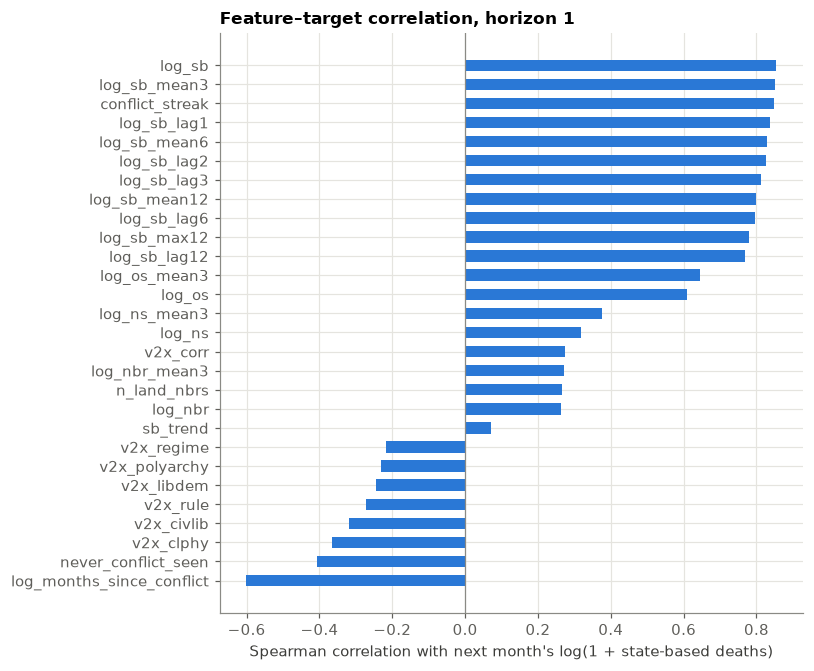

Own state-based history: rho 0.77-0.86. One-sided deaths: ~0.6. Non-state: 0.3-0.4. V-Dem and neighbour features: |rho| 0.22-0.37. (Descriptive only.)


In [6]:
d1 = make_supervised(feat, horizon=1)
d1 = d1[d1["usable"]]
corr = d1[FEATURES].corrwith(d1["y"], method="spearman").sort_values()
fig, ax = plt.subplots(figsize=(7.5, 6.2))
ax.barh(corr.index, corr.to_numpy(), color="#2a78d6", height=0.6)
ax.axvline(0, color="#8a8a85", linewidth=0.8)
ax.set_xlabel("Spearman correlation with next month's log(1 + state-based deaths)")
ax.set_title("Feature–target correlation, horizon 1")
plt.tight_layout(); plt.show()
print("Own state-based history: rho 0.77-0.86. One-sided deaths: ~0.6. Non-state: 0.3-0.4. V-Dem and neighbour features: |rho| 0.22-0.37. (Descriptive only.)")

## 4. Rows and onset counts per fold

Row counts after the usable filter, and the number of at-risk rows and onset events per fold at each horizon. Per-fold onset counts are small; the headline onset metric pools folds 1–5.

In [7]:
rows = []
for h in (1, 3, 6, 12):
    d = make_supervised(feat, horizon=h)
    d = d[d["usable"]]
    d["event"] = d["at_risk"] & (d["raw_y"] >= K_ONSET)
    for f in FOLDS:
        tr, va = fold_masks(d, f)
        rows.append({"horizon": h, "fold": f.name, "train rows": int(tr.sum()), "validation rows": int(va.sum()),
                     "at-risk (val)": int(d.loc[va, "at_risk"].sum()), "onset events (val)": int(d.loc[va, "event"].sum())})
cnt = pd.DataFrame(rows)
display(cnt.pivot(index="fold", columns="horizon", values="onset events (val)").rename_axis(columns="onset events by horizon"))
display(cnt[cnt["horizon"] == 1].drop(columns="horizon").set_index("fold"))

onset events by horizon,1,3,6,12
fold,,,,
fold 1,25,34,45,63
fold 2,24,34,46,51
fold 3,23,32,43,67
fold 4,27,39,51,70
fold 5,29,38,49,69


,train rows,validation rows,at-risk (val),onset events (val)
fold,,,,
fold 1,31012,6053,5397,25
fold 2,37065,6118,5489,24
fold 3,43183,6149,5471,23
fold 4,49332,6156,5344,27
fold 5,55488,6156,5340,29


## 5. Save

In [8]:
cols = ["gwno", "country", "month", "sb_best", "usable", "at_risk", "months_observed", *FEATURES]
out = feat[cols].copy()
out["month"] = out["month"]          # timestamp (first of month)
out_path = PROCESSED / "features.parquet"
out.to_parquet(out_path, index=False)
print(f"Saved {out_path.relative_to(root)}: {out.shape[0]:,} rows × {out.shape[1]} columns "
      f"({int(out['usable'].sum()):,} usable origins)")

Saved data\processed\features.parquet: 75,703 rows × 35 columns (72,079 usable origins)
